<a href="https://colab.research.google.com/github/OluPaul22/gis/blob/main/NJ_Retail_Supply_External_Demand_Rebuild_2022_2024_v3_Roster_Update.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NJ retail supply and external demand rebuild, 2022–2024

This notebook sets up the research dataset rebuild. The input is the audited retailer-location workbook, and the target is the 2016–2024 municipality-year panel. The 2022 origins matter because those locations may supply retail access in 2023 and 2024.

The retailer workbook's operation dates are **license-commencement proxies**, except where the evidence identifies an actual sales commencement. Keep the date basis and review flags alongside the results. The existing `optout5`–`optout20` measures describe nearby populations in municipalities that did not opt in. New **no-retail** demand measures must instead use annual retailer counts.

Run the package and import cells first. The Drive mount and input checks are separate so no source file is changed by setup.


## 1. Install packages

In [ ]:
%pip -q install pandas numpy openpyxl pyreadstat geopandas pyogrio shapely pyproj scipy matplotlib statsmodels linearmodels


## 2. Import packages

In [ ]:
from pathlib import Path
from datetime import date, datetime

import numpy as np
import pandas as pd
import geopandas as gpd
import openpyxl
import pyreadstat
import pyogrio
import shapely
import pyproj
from scipy.spatial import cKDTree
import matplotlib.pyplot as plt
import statsmodels.api as sm
from linearmodels.panel import PanelOLS

print(f"pandas {pd.__version__} | geopandas {gpd.__version__} | numpy {np.__version__}")
print("Rebuild packages imported successfully.")


pandas 2.2.3 | geopandas 1.2.0 | numpy 2.1.3
Rebuild packages imported successfully.


## 3. Connect Drive when the input files are ready

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 4. Set input and output paths

In [ ]:
PROJECT_DIR = Path('/content/drive/MyDrive/2026_Dr. Hayes_SummerProjects/CannabisGISproject')
GIS_DIR = PROJECT_DIR / 'NJ_Municipal_Boundaries_3424'
GEO_DATA_DIR = GIS_DIR / 'created_datasets'

# Audited workbook is in the existing created_datasets folder.
RETAILER_WORKBOOK = GEO_DATA_DIR / 'Main_NJOperation_Proxies_2022-2024.xlsx'
BASE_PANEL = PROJECT_DIR / 'can_modified_upd.dta'
MUNICIPALITY_REFERENCE = GEO_DATA_DIR / 'mun_geo.csv'
MUNICIPALITY_PAIRS = GEO_DATA_DIR / 'mun_pairs_20mi.csv'

# No output folder is created until the rebuild begins.
REBUILD_DIR = PROJECT_DIR / 'retail_supply_rebuild_2022_2024'

inputs = {
    'audited retailer workbook': RETAILER_WORKBOOK,
    'updated base panel': BASE_PANEL,
    'municipality reference': MUNICIPALITY_REFERENCE,
    'municipality distance matrix': MUNICIPALITY_PAIRS,
}
for label, path in inputs.items():
    print(f"{'FOUND' if path.is_file() else 'MISSING'} | {label} | {path}")


FOUND | audited retailer workbook | /content/drive/MyDrive/2026_Dr. Hayes_SummerProjects/CannabisGISproject/NJ_Municipal_Boundaries_3424/created_datasets/Main_NJOperation_Proxies_2022-2024.xlsx
FOUND | updated base panel | /content/drive/MyDrive/2026_Dr. Hayes_SummerProjects/CannabisGISproject/can_modified_upd.dta
FOUND | municipality reference | /content/drive/MyDrive/2026_Dr. Hayes_SummerProjects/CannabisGISproject/NJ_Municipal_Boundaries_3424/created_datasets/mun_geo.csv
FOUND | municipality distance matrix | /content/drive/MyDrive/2026_Dr. Hayes_SummerProjects/CannabisGISproject/NJ_Municipal_Boundaries_3424/created_datasets/mun_pairs_20mi.csv


## 5. Read-only input inspection

In [ ]:
if all(path.is_file() for path in inputs.values()):
    retailer_sheet = pd.read_excel(RETAILER_WORKBOOK, sheet_name='Main dataset')
    base_panel = pd.read_stata(BASE_PANEL, convert_categoricals=False)
    municipality_ref = pd.read_csv(MUNICIPALITY_REFERENCE, dtype={'muni_id': str})
    municipality_pairs = pd.read_csv(
        MUNICIPALITY_PAIRS,
        dtype={'muni_a_id': str, 'muni_b_id': str},
    )

    print('Retailer rows:', len(retailer_sheet))
    print('Base panel rows:', len(base_panel))
    print('Base panel municipality-years duplicated:',
          base_panel.duplicated(['muni_id', 'year']).sum())
    print('Municipalities:', municipality_ref['muni_id'].nunique())
    print('Distance-matrix pairs:', len(municipality_pairs))
    display(retailer_sheet.head(5))
else:
    print('Place the missing inputs in the paths above before loading data.')


Retailer rows: 196
Base panel rows: 5085
Base panel municipality-years duplicated: 0
Municipalities: 564
Distance-matrix pairs: 47966


,Municipality / locality,Proxy year,Retail address,Retailer,Approval date,Operation-date proxy,Reported open-by date (meeting slide),Renewal decision date,Date basis,Review flag
0,Bellmawr,2022,"640 Creek Rd, Bellmawr, NJ 08031",Curaleaf NJ II,2022-04-11,2022-04-21,NaT,2024-03-13,CRC issuance,Legacy ATC
1,Bloomfield,2022,"26-48 Bloomfield Ave, Bloomfield, NJ 07003",GTI New Jersey LLC,2022-04-11,2022-04-21,NaT,2024-03-13,CRC issuance,Legacy ATC
2,Bordentown,2022,"191 Route 130, Bordentown, NJ 08505",Curaleaf NJ II,2022-10-27,2022-10-31,NaT,2024-09-19,CRC issuance,Legacy ATC
3,Deptford,2022,"1692 Clements Bridge Rd, Deptford, NJ 08096",Columbia Care dba The Cannabist,2022-04-11,2022-04-21,NaT,2024-03-13,CRC issuance,Legacy ATC
4,Eatontown,2022,"59 NJ-35, Eatontown, NJ 07724",Ayr Wellness NJ LLC,2022-05-24,2022-06-06,NaT,2024-04-11,CRC issuance,Legacy ATC


## Rebuild sequence

1. Match each **retail location** and address to a legal New Jersey municipality ID. Audit duplicate licenses, relocations, missing dates, and coverage before assigning zero counts.
2. Expand each location into annual 2022–2024 year-end status, retaining its evidence class. Aggregate to retailer counts by `muni_id` and `year`.
3. Merge counts with the 2016–2024 base panel. Keep the old presentation variables separate. For adult-use retail, verify the pre-2022 zero assumption and do not infer 2022–2024 zeros from an incomplete inventory.
4. Reuse the municipality-centroid distance matrix. For each focal municipality-year and radius, sum populations in **other municipalities with zero retailers**. Call these `no_retail_pop5`, `no_retail_pop10`, `no_retail_pop15`, and `no_retail_pop20`. Preserve `optout5`–`optout20` as distinct policy measures.
5. Create retail-supply × external-demand interactions and competition measures; check counts, joins, distance ordering, and alternative evidence rules before modeling.

The package and input checks above do not execute this rebuild or overwrite prior datasets.


In [ ]:
base_panel = pd.read_stata(BASE_PANEL, convert_categoricals=False)
municipality_ref = pd.read_csv(MUNICIPALITY_REFERENCE, dtype=str)
municipality_pairs = pd.read_csv(MUNICIPALITY_PAIRS, dtype=str)
print('PANEL', base_panel.shape, list(base_panel.columns))
print('PANEL KEY', base_panel[['muni_id','year']].head().to_dict('records'))
print('REFERENCE', municipality_ref.shape, list(municipality_ref.columns), municipality_ref.head(3).to_dict('records'))
print('PAIRS', municipality_pairs.shape, list(municipality_pairs.columns), municipality_pairs.head(3).to_dict('records'))
print('YEARS', base_panel['year'].value_counts().sort_index().to_dict())

PANEL (5085, 15) ['muni_id', 'muni_name', 'year', 'can_rev', 'can_rev_pcap', 'can_active', 'opted_in', 'eff_tax_rate', 'mri_score', 'dem_vote', 'eqprop_val', 'state_rev', 'pop', 'age65_over', 'ihs_can_rev_pcap']
PANEL KEY [{'muni_id': 101, 'year': 2016.0}, {'muni_id': 101, 'year': 2017.0}, {'muni_id': 101, 'year': 2018.0}, {'muni_id': 101, 'year': 2019.0}, {'muni_id': 101, 'year': 2020.0}]
REFERENCE (564, 7) ['muni_id', 'muni_name', 'county', 'muni_label', 'muni_type', 'latitude', 'longitude'] [{'muni_id': '0503', 'muni_name': 'Cape May Point Borough', 'county': 'CAPE MAY', 'muni_label': 'Cape May Point Borough', 'muni_type': 'Borough', 'latitude': '38.93732672689051', 'longitude': '-74.96519625276774'}, {'muni_id': '0512', 'muni_name': 'West Cape May Borough', 'county': 'CAPE MAY', 'muni_label': 'West Cape May Borough', 'muni_type': 'Borough', 'latitude': '38.94226766777276', 'longitude': '-74.93779313642504'}, {'muni_id': '0502', 'muni_name': 'Cape May', 'county': 'CAPE MAY', 'muni_l

In [ ]:
import re
def place_key(value):
    value = re.sub(r'[^a-z0-9 ]', ' ', str(value).lower())
    value = re.sub(r'\b(township|borough|city|town|village|twp)\b', ' ', value)
    return re.sub(r'\s+', ' ', value).strip()
ref = municipality_ref.copy()
ref['key'] = ref['muni_name'].map(place_key)
src = retailer_sheet[['Municipality / locality', 'Retail address']].copy()
src['key'] = src['Municipality / locality'].map(place_key)
counts = ref.groupby('key')['muni_id'].nunique()
print('Unmatched source localities:', sorted(set(src['key']) - set(ref['key'])))
print('Ambiguous matches:', {k:int(counts[k]) for k in set(src['key']) & set(ref['key']) if counts[k] > 1})
print('Panel IDs missing from reference:', sorted(set(base_panel['muni_id'].astype(int).astype(str).str.zfill(4)) - set(ref['muni_id'])))
print('Reference IDs missing from panel:', sorted(set(ref['muni_id']) - set(base_panel['muni_id'].astype(int).astype(str).str.zfill(4))))

Unmatched source localities: ['atco', 'blackwood', 'hewitt', 'kingston', 'marlton', 'mouth ephraim', 'n brunswick', 'n cape may', 'newfoundland', 's bound brook', 'sicklerville', 'somerset', 'turnersville', 'waretown', 'williamstown']
Ambiguous matches: {'bordentown': 2, 'washington': 6, 'freehold': 2, 'harrison': 2, 'egg harbor': 2, 'boonton': 2, 'raritan': 2, 'rockaway': 2, 'andover': 2, 'union': 3, 'neptune': 2, 'lawrence': 2}
Panel IDs missing from reference: ['0429']
Reference IDs missing from panel: []


In [ ]:
def full_key(value):
    return re.sub(r'\s+', ' ', re.sub(r'[^a-z0-9 ]', ' ', str(value).lower())).strip()

geo = municipality_ref.copy()
geo['muni_id'] = geo['muni_id'].str.zfill(4)
geo['full_key'] = geo['muni_name'].map(full_key)
geo['short_key'] = geo['muni_name'].map(place_key)
full_ids = geo.groupby('full_key')['muni_id'].agg(list).to_dict()
full_ids.pop('bordentown', None)  # Both source sites are in Bordentown Township.
short_ids = geo.groupby('short_key')['muni_id'].agg(list).to_dict()

# Postal localities and same-name municipalities need an address-level crosswalk.
# These are research matches to audit against official municipal records.
postal_ids = {
    'atco':'0435', 'blackwood':'0415', 'hewitt':'1615',
    'kingston':'1808', 'marlton':'0313', 'mouth ephraim':'0425',
    'n brunswick':'1215', 'n cape may':'0505', 'newfoundland':'1615',
    's bound brook':'1819', 'sicklerville':'0415', 'somerset':'1808',
    'turnersville':'0818', 'waretown':'1520', 'williamstown':'0811',
    'andover':'1901', 'boonton':'1401', 'bordentown':'0304',
    'freehold':'1315', 'harrison':'0904', 'lawrence':'1107',
    'neptune':'1334', 'raritan':'1816', 'union':'2019',
    'washington':'2121',
}
retailer_ids = {'Kind Kush':'1434', 'G2 Dispensary':'1434',
                'Holistic Re-Leaf':'1435'}

def map_location(row):
    locality = row['Municipality / locality']
    exact = full_ids.get(full_key(locality), [])
    if len(exact) == 1:
        return pd.Series((exact[0], 'exact legal name', False))
    short = short_ids.get(place_key(locality), [])
    if len(short) == 1:
        return pd.Series((short[0], 'unique normalized name', False))
    if row['Retailer'] in retailer_ids:
        return pd.Series((retailer_ids[row['Retailer']], 'address-specific research crosswalk', True))
    code = postal_ids.get(place_key(locality))
    if code:
        return pd.Series((code, 'postal/locality research crosswalk', True))
    return pd.Series((pd.NA, 'unresolved', True))

locations = retailer_sheet.copy()
locations[['muni_id','mapping_method','address_review_needed']] = locations.apply(map_location, axis=1)
locations = locations.merge(geo[['muni_id','muni_name','county']], on='muni_id', how='left', validate='many_to_one')
print('Locations:',len(locations),'matched:',locations['muni_id'].notna().sum())
print('Research crosswalk rows:',int(locations['address_review_needed'].sum()))
print('Missing legal IDs:',locations.loc[locations['muni_id'].isna(),['Retailer','Retail address']].to_dict('records'))
print(locations.groupby('mapping_method').size().to_dict())
assert locations['muni_id'].notna().all()
assert locations['muni_name'].notna().all()
CONFIRMED_ADDRESS_MATCHES = [('4Twenty Somewhere', '1938 Union Valley Rd Hewitt, NJ 07421', '1615'), ('Acreage CCF', '2090 N Black Horse Pike, Williamstown, NJ 08094', '0811'), ('Andover Cannabis', '144 Main Street #146 Andover, NJ 07821', '1901'), ('Ayr Wellness NJ LLC', '2536 Route 22, Union, NJ 07083', '2019'), ('BLOC', '1075 Easton Ave., Somerset, NJ 08873', '1808'), ('BLOC', '501 Route 9, Unit 6 Waretown, NJ 08758', '1520'), ('Bleachers Dispensary', '1165 Route 27 Somerset NJ 08873', '1808'), ('Botera Union', '2290 Rt 22 East, Union, NJ 07083', '2019'), ('Brotherly Bud LLC', '500 N Black Horse Pike, Mount Ephraim, NJ 08059', '0425'), ("Buddy's Dispensary", '203 Main St., #1 Andover, NJ 07821', '1901'), ('Citi Roots', '4585 Route 27 Kingston, NJ 08528', '1808'), ('Curaleaf NJ II', '191 Route 130, Bordentown, NJ 08505', '0304'), ('Dank Poet Dispensary', '245 E. Washington Ave., Washington, NJ 07882', '2121'), ('Enlighten Health & Wellness', '781 Route 70 W Marlton, NJ 08053', '0313'), ('Evolve Cannabis', '186 Route 130, Bordentown NJ 08505', '0304'), ('Flower & Flame', '601 College Dr, Blackwood, NJ 08012', '0415'), ('G2 Dispensary', '350 Route 46 Suite 121 Rockaway, NJ 07866', '1434'), ('Green Oasis Dispensary', '632 White Horse Pike, Atco, NJ 08004', '0435'), ("Herb's Premium Dispensary", '757 Franklin Blvd Somerset, NJ 08873', '1808'), ('Holistic Re-Leaf', '321 Mount Hope Ave., Rockaway NJ 07866', '1435'), ('Holistic Solutions', '451 White Horse Pike, Atco, NJ 08004', '0435'), ('Kind Kush', '279 Rt. 46, Rockaway, NJ 07866', '1434'), ('Leaf Haus LLC', '900 Easton Ave., Ste. 18, Somerset NJ 08873', '1808'), ('MPX NJ', '581 Berlin - Cross Keys Rd. Units A-B Sicklerville, NJ 08081', '0415'), ('Midnight Greens', '5100 Route 42 Turnersville, NJ 08012', '0818'), ('NJ Leaf', '546 Park Ave, Freehold, NJ 07728', '1315'), ('NJ Leaf North Brunswick', '1345 Route 1 N Brunswick, NJ 08902', '1215'), ('RushBudz Dispensary', '77 Main Street, S Bound Brook, NJ 08880', '1819'), ('Sea & Leaf', '3860 Bayshore Rd STE 7 N Cape May, NJ 08204', '0505'), ('Soulflora Inc', '2713 NJ-23 #5A, Newfoundland, NJ, NJ 07435', '1615'), ('The Dispensary of Somerset', '920 Hamilton St. #950, Somerset, NJ 08873', '1808'), ('The Dispensary of Union', '1603 Rt 22 W., Union, NJ 07083', '2019'), ('Timber 5', '695 Hamilton St., Somerset, NJ 08873', '1808'), ('Unity Rd Cannabis Shop', '441 Elizabeth Ave, Ste 12, Somerset NJ 08873', '1808'), ('Valley Wellness', '407 Route 202 Raritan, NJ 08869', '1816'), ('Verano NJ', '2100 State Route 66, Neptune, NJ 07753', '1334'), ('Verano NJ', '3256 Brunswick Pike, Lawrence, NJ 08648', '1107')]

# The researcher checked these 37 address-level matches in retailer_location_review.xlsx
# on 2026-10-08. Match all three fields so a changed address cannot inherit approval.
confirmed_address_matches = set(CONFIRMED_ADDRESS_MATCHES)
actual_address_matches = set(
    (str(r['Retailer']), str(r['Retail address']), str(r['muni_id']))
    for _, r in locations.loc[locations['address_review_needed']].iterrows()
)
assert {(retailer, muni_id) for retailer, address, muni_id in actual_address_matches} == {(retailer, muni_id) for retailer, address, muni_id in confirmed_address_matches}
locations['address_confirmation'] = np.where(
    locations['address_review_needed'], 'researcher confirmed 2026-10-08',
    'direct or unique municipality match')
locations['confirmed_crosswalk'] = locations['address_review_needed'].astype(int)
locations['address_review_needed'] = False
assert locations['confirmed_crosswalk'].sum() == 37
print('Address-based matches confirmed:', int(locations['confirmed_crosswalk'].sum()))


Locations: 196 matched: 196
Research crosswalk rows: 37
Missing legal IDs: []
{'address-specific research crosswalk': 3, 'exact legal name': 72, 'postal/locality research crosswalk': 34, 'unique normalized name': 87}
Address-based matches confirmed: 37


In [ ]:
details = pd.read_excel(RETAILER_WORKBOOK, sheet_name='Date details', header=3)
keep = ['Municipality / locality','Retailer','Retail license','Location end evidence',
        'Documented commencement','Renewed expiration','Years subtracted']
locations = locations.merge(details[keep], on=['Municipality / locality','Retailer'],
                            how='left', validate='one_to_one')
locations['proxy_date'] = pd.to_datetime(locations['Operation-date proxy'], errors='coerce')
locations['open_by_date'] = pd.to_datetime(locations['Reported open-by date (meeting slide)'], errors='coerce')
locations['approval_date'] = pd.to_datetime(locations['Approval date'], errors='coerce')
locations['end_date'] = pd.to_datetime(locations['Location end evidence'], errors='coerce')
locations['start_year'] = locations['Proxy year'].astype(int)
locations['year_basis'] = np.where(locations['proxy_date'].notna(),
                                   'license commencement proxy year', 'open-by bound year')
assert (locations.loc[locations['proxy_date'].notna(),'proxy_date'].dt.year ==
        locations.loc[locations['proxy_date'].notna(),'start_year']).all()
assert locations.loc[locations['proxy_date'].isna(),'open_by_date'].notna().all()
assert locations['Retail license'].dropna().duplicated().sum() == 1  # Montclair-to-Wharton relocation

# One recorded site counts as one in every December 31 count from its start year
# until the first documented end date. This is the primary supply definition.
site_year = locations.assign(_join=1).merge(
    pd.DataFrame({'year':[2022,2023,2024], '_join':1}), on='_join').drop(columns='_join')
site_year['year_start'] = pd.to_datetime(site_year['year'].astype(str) + '-01-01')
site_year['next_year_start'] = pd.to_datetime((site_year['year']+1).astype(str) + '-01-01')
site_year['year_end'] = site_year['next_year_start'] - pd.Timedelta(days=1)
site_year['days_in_year'] = (site_year['next_year_start']-site_year['year_start']).dt.days
site_year['observed_active_at_year_end'] = ((site_year['year'] >= site_year['start_year']) &
    (site_year['end_date'].isna() | (site_year['end_date'] > site_year['year_end'])))

# Secondary sensitivity: site days in [commencement, documented end), divided by
# 365 or 366. The end date is treated as the first non-operating date.
effective_start = site_year[['proxy_date','year_start']].max(axis=1)
effective_end = site_year[['end_date','next_year_start']].min(axis=1)
site_year['retail_days_known'] = (effective_end-effective_start).dt.days.clip(lower=0)
site_year.loc[site_year['year'].lt(site_year['start_year']),'retail_days_known'] = 0
unknown_start = site_year['proxy_date'].isna() & site_year['year'].eq(site_year['start_year'])
site_year.loc[unknown_start,'retail_days_known'] = np.nan
site_year['retail_days_lower'] = site_year['retail_days_known']
site_year['retail_days_upper'] = site_year['retail_days_known']
site_year.loc[unknown_start,'retail_days_lower'] = (
    effective_end[unknown_start]-site_year.loc[unknown_start,'open_by_date']).dt.days.clip(lower=0)
site_year.loc[unknown_start,'retail_days_upper'] = (
    effective_end[unknown_start]-site_year.loc[unknown_start,'year_start']).dt.days.clip(lower=0)
for suffix in ('known','lower','upper'):
    site_year[f'retail_exposure_{suffix}'] = site_year[f'retail_days_{suffix}']/site_year['days_in_year']
assert (site_year['retail_days_lower'] <= site_year['retail_days_upper']).all()
assert site_year['retail_days_upper'].le(site_year['days_in_year']).all()

active_sites = site_year[site_year['observed_active_at_year_end']].copy()
retailer_counts = active_sites.groupby(['muni_id','year'],as_index=False).agg(
    retail_supply_observed=('Retailer','size'),
    renewal_estimate_sites=('Date basis',lambda x:(x=='Renewal estimate').sum()),
    crc_issuance_sites=('Date basis',lambda x:(x=='CRC issuance').sum()),
    confirmed_crosswalk_sites=('confirmed_crosswalk','sum'))
exposure = site_year.groupby(['muni_id','year'],as_index=False).agg(
    retail_supply_time_weighted=('retail_exposure_known',lambda x: x.sum() if x.notna().all() else np.nan),
    retail_supply_time_weighted_lower=('retail_exposure_lower','sum'),
    retail_supply_time_weighted_upper=('retail_exposure_upper','sum'),
    sites_with_unknown_exact_start=('retail_days_known',lambda x:x.isna().sum()))

panel = base_panel.copy()
panel['muni_id'] = panel['muni_id'].astype(int).astype(str).str.zfill(4)
panel['year'] = panel['year'].astype(int)
# Pine Valley (0429) merged into Pine Hill in 2022. Drop its rows in every year
# to keep the same 564 municipal units; do not silently add its old values to Pine Hill.
assert panel.loc[panel.muni_id.eq('0429')].shape[0] == 9
panel = panel.loc[panel.muni_id.ne('0429')].copy()
panel = panel.merge(retailer_counts,on=['muni_id','year'],how='left',validate='one_to_one')
panel = panel.merge(exposure,on=['muni_id','year'],how='left',validate='one_to_one')
panel['retail_supply_observed'] = panel['retail_supply_observed'].fillna(0).astype(int)
panel['retailer_present_observed'] = (panel['retail_supply_observed'] > 0).astype(int)
for c in ('retail_supply_time_weighted','retail_supply_time_weighted_lower',
          'retail_supply_time_weighted_upper'):
    panel[c] = panel[c].fillna(0).where(
        ~(panel['muni_id'].eq('1438') & panel['year'].eq(2024) &
          (c == 'retail_supply_time_weighted')), np.nan)
panel['sites_with_unknown_exact_start'] = panel['sites_with_unknown_exact_start'].fillna(0).astype(int)
panel.loc[panel['sites_with_unknown_exact_start'].gt(0),'retail_supply_time_weighted'] = np.nan
panel['retail_supply_scope'] = 'recorded CRC locations; historical statewide completeness not established'
assert panel.shape[0] == 564*9
assert not panel.duplicated(['muni_id','year']).any()
print('Year-end recorded sites:',active_sites.groupby('year').size().to_dict())
print('Confirmed crosswalk sites:',int(locations['confirmed_crosswalk'].sum()))
print('Panel:',panel.shape,'municipalities:',panel.muni_id.nunique())
print('Unknown time-weighted municipality-years:',
      panel.loc[panel.sites_with_unknown_exact_start.gt(0),['muni_name','year']].to_dict('records'))


Year-end recorded sites: {2022: 21, 2023: 84, 2024: 195}
Confirmed crosswalk sites: 37
Panel: (5076, 25) municipalities: 564
Unknown time-weighted municipality-years: [{'muni_name': 'Wharton Boro', 'year': 2024}]


In [ ]:
pairs = municipality_pairs[['muni_a_id','muni_b_id','distance_miles']].copy()
pairs['distance_miles'] = pd.to_numeric(pairs['distance_miles'], errors='raise')
pairs = pairs[pairs['muni_a_id'] != pairs['muni_b_id']]
assert not pairs.duplicated(['muni_a_id','muni_b_id']).any()
assert pairs['distance_miles'].ge(0).all()

neighbor_year = panel.loc[panel['year'].between(2022,2024),
    ['muni_id','year','pop','retail_supply_observed']].copy()
neighbor_year['pop'] = pd.to_numeric(neighbor_year['pop'], errors='coerce')
neighbor_year = neighbor_year.rename(columns={'muni_id':'muni_b_id',
    'pop':'neighbor_pop','retail_supply_observed':'neighbor_retailers'})
near = pairs.merge(neighbor_year, on='muni_b_id', how='left', validate='many_to_many')
assert len(near) == len(pairs)*3
assert near['year'].notna().all()
near['year'] = near['year'].astype(int)

for miles in (5,10,15,20):
    subset = near[near['distance_miles'] <= miles].copy()
    subset['included_pop'] = np.where(subset['neighbor_retailers'].eq(0),
                                       subset['neighbor_pop'], 0)
    subset['missing_pop'] = (subset['neighbor_retailers'].eq(0) &
                             subset['neighbor_pop'].isna()).astype(int)
    summaries = subset.groupby(['muni_a_id','year'],as_index=False).agg(
        nearby_pop_without_recorded_retail=('included_pop','sum'),
        missing_neighbor_pop=('missing_pop','sum'),
        nearby_recorded_retailers=('neighbor_retailers','sum'))
    demand_col = f'nearby_pop_without_recorded_retail{miles}'
    competition_col = f'nearby_recorded_retailers{miles}'
    summaries = summaries.rename(columns={'muni_a_id':'muni_id',
        'nearby_pop_without_recorded_retail':demand_col,
        'nearby_recorded_retailers':competition_col})
    summaries.loc[summaries['missing_neighbor_pop'] > 0,demand_col] = np.nan
    summaries = summaries.drop(columns='missing_neighbor_pop')
    panel = panel.merge(summaries,on=['muni_id','year'],how='left',validate='one_to_one')
    valid_geo = panel['muni_id'].isin(geo['muni_id']) & panel['year'].between(2022,2024)
    no_neighbors = valid_geo & panel[competition_col].isna()
    panel.loc[no_neighbors,[demand_col,competition_col]] = 0

print('2022–2024 missing population rows:',int(neighbor_year['neighbor_pop'].isna().sum()))
print('2024 demand missing by radius:',
      {r:int(panel.loc[panel.year==2024,f'nearby_pop_without_recorded_retail{r}'].isna().sum())
       for r in (5,10,15,20)})
print('Panel rows and columns:',panel.shape)
print('Pine Valley 0429 removed; every retained panel ID has a geographic match.')
print(panel.loc[(panel.year==2024)&(panel.retail_supply_observed>0),
      ['muni_name','retail_supply_observed','nearby_pop_without_recorded_retail10']].head(5).to_string(index=False))

2022–2024 missing population rows: 0
2024 demand missing by radius: {5: 0, 10: 0, 15: 0, 20: 0}
Panel rows and columns: (5076, 33)
Pine Valley 0429 removed; every retained panel ID has a geographic match.
      muni_name  retail_supply_observed  nearby_pop_without_recorded_retail10
  Atlantic City                      13                               95775.0
     Buena Boro                       1                               31210.0
Egg Harbor City                       1                               73403.0
 Egg Harbor Twp                       4                               63686.0
 Hammonton Town                       1                               55250.0


In [ ]:
from zipfile import ZipFile, ZIP_DEFLATED

for miles in (5,10,15,20):
    a = panel.loc[panel.year.between(2022,2024),f'nearby_pop_without_recorded_retail{miles}']
    assert a.dropna().ge(0).all()
    b = panel.loc[panel.year.between(2022,2024),f'nearby_recorded_retailers{miles}']
    assert b.dropna().ge(0).all()
for r1,r2 in ((5,10),(10,15),(15,20)):
    subset = panel[panel.year.between(2022,2024)]
    low = subset[f'nearby_pop_without_recorded_retail{r1}']
    high = subset[f'nearby_pop_without_recorded_retail{r2}']
    valid = low.notna() & high.notna()
    assert (low[valid] <= high[valid]).all()
    low = subset[f'nearby_recorded_retailers{r1}']
    high = subset[f'nearby_recorded_retailers{r2}']
    valid = low.notna() & high.notna()
    assert (low[valid] <= high[valid]).all()
assert active_sites.groupby('year').size().to_dict() == {2022:21,2023:84,2024:195}

screened_panel = panel.copy()
first_year = active_sites.groupby('muni_id')['year'].min().rename('first_retail_year_recorded')
screened_panel = screened_panel.merge(first_year,on='muni_id',how='left',validate='many_to_one')
screened_panel['years_since_first_recorded'] = np.where(
    screened_panel.year >= screened_panel.first_retail_year_recorded,
    screened_panel.year - screened_panel.first_retail_year_recorded, np.nan)
screened_panel['analysis_eligible_geo'] = True
for miles in (5,10,15,20):
    screened_panel[f'retail_x_nrpop{miles}_screen'] = (
        screened_panel['retail_supply_observed'] *
        screened_panel[f'nearby_pop_without_recorded_retail{miles}'])

source_links = pd.read_excel(RETAILER_WORKBOOK, sheet_name='Source links', header=3)
urls = source_links.pivot(index=['Municipality / locality','Retailer'],
                          columns='Source type',values='URL').reset_index()
location_review = locations.merge(urls,on=['Municipality / locality','Retailer'],
                                  how='left',validate='one_to_one')
location_review['source_workbook'] = RETAILER_WORKBOOK.name

output_dir = Path('/content/nj_retail_rebuild_preview')
output_dir.mkdir(parents=True,exist_ok=True)
location_review.to_csv(output_dir/'retailer_location_review.csv',index=False)
site_year.to_csv(output_dir/'recorded_retailer_years.csv',index=False)
screened_panel.to_csv(output_dir/'municipality_panel_screened_2016_2024.csv',index=False)
rename = {'retail_supply_observed':'retail_n_screen',
          'retailer_present_observed':'retail_any_screen',
          'retail_supply_time_weighted':'retail_wt_screen',
          'retail_supply_time_weighted_lower':'retail_wt_lo_screen',
          'retail_supply_time_weighted_upper':'retail_wt_hi_screen',
          'retail_supply_scope':'supply_scope'}
for miles in (5,10,15,20):
    rename[f'nearby_pop_without_recorded_retail{miles}'] = f'nrpop{miles}_screen'
    rename[f'nearby_recorded_retailers{miles}'] = f'nearret{miles}_screen'
statapanel = screened_panel.rename(columns=rename)
statapanel.to_stata(output_dir/'municipality_panel_screened_2016_2024.dta',
                    write_index=False,version=118)
readme = ("PRELIMINARY RESEARCH DATA — NOT THE FINAL PAPER VARIABLES\n"
"The 196-location workbook is not a certified statewide census. Retail counts are recorded-site counts, not verified total active retailers. Nearby population without a recorded retailer is not proof of no retail access. All 37 address-based municipality crosswalk rows were confirmed by the researcher on 2026-10-08. The workbook dates are license-commencement proxies except where documented otherwise. Continued operation is assumed absent end evidence. Demand is computed only for 2022–2024. Pine Valley ID 0429 is removed for a consistent 564-municipality panel. Time-weighted supply is a secondary sensitivity measure; Wharton 2024 has bounds because only an open-by date is known. The old optout variables measure policy choice and are distinct from no-retail demand. Original sources and date rules are in Main_NJOperation_Proxies_2022-2024.xlsx.\n")
(output_dir/'README.txt').write_text(readme)
with ZipFile(output_dir/'nj_retail_rebuild_preview.zip','w',ZIP_DEFLATED) as z:
    for path in output_dir.iterdir():
        if path.name != 'nj_retail_rebuild_preview.zip': z.write(path,arcname=path.name)
print('Preview files:',[(p.name,p.stat().st_size) for p in output_dir.iterdir()])
print('Mapped retailer rows:',len(location_review),'municipality-year rows:',len(screened_panel))

Preview files: [('README.txt', 916), ('recorded_retailer_years.csv', 248389), ('municipality_panel_screened_2016_2024.csv', 1304951), ('retailer_location_review.csv', 142272), ('nj_retail_rebuild_preview.zip', 499530), ('municipality_panel_screened_2016_2024.dta', 1807831)]
Mapped retailer rows: 196 municipality-year rows: 5076


In [ ]:
from google.colab import files
files.download(str(output_dir / 'nj_retail_rebuild_preview.zip'))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Adopted decisions and interpretation

The primary retail-supply variable is the **December 31 count** of recorded Class 5 retail locations. A location enters in the year of its license-commencement proxy and remains in subsequent year-end counts until documented closure or relocation. This implements the paper's count convention even if the proxy date falls late in the year. The exact date is a license-based proxy for opening, not observed first sales.

`retail_supply_time_weighted` is a secondary sensitivity measure: for each location, count days from the proxy commencement date through the day before any documented end, divided by 365 or 366, then add locations within a municipality-year. A retailer starting October 1 contributes about 0.25 in that year and 1 in a later full year. This checks whether conclusions depend on treating a late-year entrant as a full retailer for the entire year. It is not a replacement for the primary count. Wharton's 2024 exact start is unknown; its weighted result is missing, with lower and upper bounds based on its documented open-by date. Montclair's documented 2024 relocation end contributes only its pre-move days to the weighted measure.

All **37 address-based legal-municipality matches** were confirmed by the researcher in `retailer_location_review.xlsx` on 2026-10-08 and are retained with a confirmation flag. Pine Valley ID 0429 is removed from **all years** for a consistent 564-municipality panel; historical Pine Valley values are not silently transferred to Pine Hill. Pine Hill remains.

External demand is computed separately at **5, 10, 15, and 20 miles** using the existing municipality-centroid distance matrix and populations of other municipalities with no *recorded* retailer. The 5-mile measure is first in the analysis sequence. The existing `optout5`–`optout20` variables measure policy choice and remain distinct.

This remains a **screened research preview**, because the 196-location workbook is not established as a complete statewide historical retailer census. A zero in `retail_supply_observed` means no retailer in this workbook, not verified absence of all retailers. A zero in the no-recorded-retail demand construction is subject to the same limitation. Original dates and document links are in the source workbook and the [NJ Cannabis Regulatory Commission awardees and renewals](https://www.nj.gov/cannabis/businesses/license-awardees/) page.


In [ ]:
display(screened_panel.loc[screened_panel.year.isin([2022,2023,2024]),
    ['muni_id','muni_name','year','retail_supply_observed',
     'retail_supply_time_weighted','retail_supply_time_weighted_lower',
     'retail_supply_time_weighted_upper','nearby_pop_without_recorded_retail5',
     'nearby_pop_without_recorded_retail10']].head(12))
print('Wharton 2024 exposure bounds:')
display(screened_panel.loc[(screened_panel.muni_name.str.contains('Wharton',case=False)) &
                           (screened_panel.year.eq(2024)),
    ['muni_name','year','retail_supply_observed','retail_supply_time_weighted',
     'retail_supply_time_weighted_lower','retail_supply_time_weighted_upper']])


,muni_id,muni_name,year,retail_supply_observed,retail_supply_time_weighted,retail_supply_time_weighted_lower,retail_supply_time_weighted_upper,nearby_pop_without_recorded_retail5,nearby_pop_without_recorded_retail10
6,0101,Absecon City,2022,0,0.000000,0.000000,0.000000,105178.0,146768.0
7,0101,Absecon City,2023,0,0.000000,0.000000,0.000000,66811.0,108352.0
8,0101,Absecon City,2024,0,0.000000,0.000000,0.000000,46285.0,87777.0
15,0102,Atlantic City,2022,0,0.000000,0.000000,0.000000,52048.0,116387.0
16,0102,Atlantic City,2023,2,1.115068,1.115068,1.115068,51885.0,116404.0
17,0102,Atlantic City,2024,13,8.120219,8.120219,8.120219,31076.0,95775.0
24,0103,Brigantine City,2022,0,0.000000,0.000000,0.000000,38487.0,128880.0
25,0103,Brigantine City,2023,0,0.000000,0.000000,0.000000,0.0,90390.0
26,0103,Brigantine City,2024,0,0.000000,0.000000,0.000000,0.0,69741.0
33,0104,Buena Boro,2022,0,0.000000,0.000000,0.000000,8898.0,31242.0


Wharton 2024 exposure bounds:


,muni_name,year,retail_supply_observed,retail_supply_time_weighted,retail_supply_time_weighted_lower,retail_supply_time_weighted_upper
3707,Wharton Boro,2024,1,NaN,0.532787,1.0


In [ ]:
# Figure 1 publication maps (November 2, 2026)
# Independent of the older rebuild cells above.
from pathlib import Path
from google.colab import drive
drive.mount('/content/drive')
PROJECT = Path('/content/drive/MyDrive/2026_Dr. Hayes_SummerProjects/CannabisGISproject')
GIS = PROJECT / 'NJ_Municipal_Boundaries_3424'
print('Municipal boundary files:')
print([str(p.relative_to(GIS)) for p in GIS.rglob('*') if p.suffix.lower() in ('.shp', '.gpkg', '.geojson')])
print('Current-panel candidates:')
print([str(p) for p in PROJECT.rglob('canexp_panel_new.dta')])


Mounted at /content/drive
Municipal boundary files:
['NJ_Municipal_Boundaries_3424.shp']
Current-panel candidates:
[]


In [ ]:
# Figure 1: verify the uploaded new panel against the Week 7 input.
import pandas as pd
import geopandas as gpd
import hashlib, json
PANEL_SOURCE = Path('/content/canexp_panel_new.dta')
print('Uploaded dataset SHA256:', hashlib.sha256(PANEL_SOURCE.read_bytes()).hexdigest())
assert hashlib.sha256(PANEL_SOURCE.read_bytes()).hexdigest() == '3ea98a3cea1a5e35b1025b2a58b6e6738b47e8311821a57bde214ea040d11535', 'Uploaded file differs from the Week 7 analysis input; review before mapping.'
figure1_panel = pd.read_stata(PANEL_SOURCE, convert_categoricals=False)
figure1_panel = figure1_panel.loc[figure1_panel.year.isin([2022,2024]), ['muni_id','muni_name','year','ret_any','ret_cnt']].copy()
figure1_panel['muni_id'] = figure1_panel.muni_id.astype(str).str.zfill(4)
figure1_boundaries = gpd.read_file(GIS / 'NJ_Municipal_Boundaries_3424.shp')
print('Boundary rows:',len(figure1_boundaries),'CRS:',figure1_boundaries.crs)
print('Boundary fields:',figure1_boundaries.columns.tolist())
print(figure1_boundaries.drop(columns='geometry').head(3).to_string(index=False))
print(figure1_panel.groupby('year').agg(municipalities=('muni_id','size'), retailer_municipalities=('ret_any','sum'), retail_sites=('ret_cnt','sum')).to_string())

Uploaded dataset SHA256: 3ea98a3cea1a5e35b1025b2a58b6e6738b47e8311821a57bde214ea040d11535
Boundary rows: 564 CRS: EPSG:3424
Boundary fields: ['MUN', 'COUNTY', 'MUN_LABEL', 'MUN_TYPE', 'NAME', 'GNIS_NAME', 'GNIS', 'SSN', 'MUN_CODE', 'CENSUS2020', 'ACRES', 'SQ_MILES', 'POP2020', 'POP2010', 'POP2000', 'POP1990', 'POP1980', 'POPDEN2020', 'POPDEN2010', 'POPDEN2000', 'POPDEN1990', 'POPDEN1980', 'geometry']
                MUN   COUNTY              MUN_LABEL MUN_TYPE                   NAME                 GNIS_NAME   GNIS  SSN MUN_CODE CENSUS2020       ACRES  SQ_MILES  POP2020  POP2010  POP2000  POP1990  POP1980  POPDEN2020  POPDEN2010  POPDEN2000  POPDEN1990  POPDEN1980
CAPE MAY POINT BORO CAPE MAY Cape May Point Borough  Borough Cape May Point Borough Borough of Cape May Point 885179 0503     0503 3400910330  192.050384  0.300079      305      291      241      248      255        1016         970         803         826         850
 WEST CAPE MAY BORO CAPE MAY  West Cape May Borough  Borou

In [ ]:
# Verify geographic identifiers against the original reference.
reference = pd.read_csv(GIS / 'created_datasets/mun_geo.csv', dtype={'muni_id':str})
print(figure1_boundaries.loc[figure1_boundaries['NAME'].str.contains('Aberdeen|Brick|Toms River|Eagleswood|Pine Hill',case=False),['SSN','MUN_CODE','NAME']].to_string(index=False))
print('Unique boundary SSN:',figure1_boundaries['SSN'].nunique())
print('Reference ID/name sample:',reference[['muni_id','muni_name']].head(3).to_dict('records'))

 SSN MUN_CODE                     NAME
0428     0428        Pine Hill Borough
1529     1530 South Toms River Borough
1507     1508      Toms River Township
1506     1507           Brick Township
1330     1301        Aberdeen Township
1508     1509      Eagleswood Township
Unique boundary SSN: 564
Reference ID/name sample: [{'muni_id': '0503', 'muni_name': 'Cape May Point Borough'}, {'muni_id': '0512', 'muni_name': 'West Cape May Borough'}, {'muni_id': '0502', 'muni_name': 'Cape May'}]


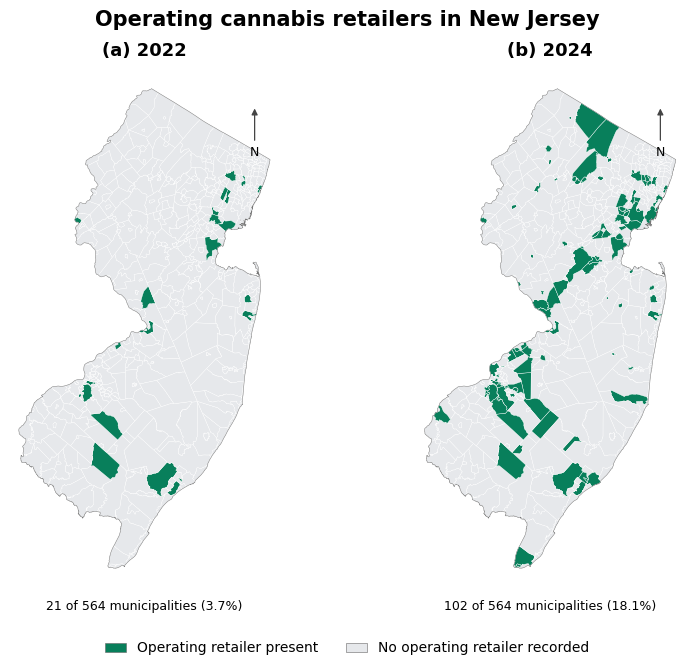

 year  municipalities  retailer_municipalities  without_retailers  percent_with_retailers  retail_sites
 2022             564                       21                543                3.723404            21
 2024             564                      102                462               18.085106           207
Verified exact 564-polygon matches for both years. Name mismatches: 0
Saved to: /content/drive/MyDrive/2026_Dr. Hayes_SummerProjects/CannabisGISproject/publication_figures_2026_11_02/Figure1


In [ ]:
# Figure 1. Retailer presence by municipality, 2022 and 2024.
# Use SSN: MUN_CODE is a different identifier for several municipalities.
import re, shutil
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from pyproj import CRS

FIGURE_DIR = PROJECT / 'publication_figures_2026_11_02' / 'Figure1'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
figure1_panel['year'] = figure1_panel.year.astype(int)
assert not figure1_panel.duplicated(['muni_id','year']).any()
assert figure1_panel.groupby('year').size().to_dict() == {2022:564,2024:564}
assert figure1_panel.ret_any.isin([0,1]).all()
assert figure1_panel.ret_any.eq(figure1_panel.ret_cnt.gt(0).astype(int)).all()
boundaries = figure1_boundaries.copy()
boundaries['muni_id'] = boundaries['SSN'].astype(str).str.zfill(4)
assert boundaries.muni_id.is_unique
assert set(boundaries.muni_id) == set(figure1_panel.muni_id) == set(reference.muni_id)
assert not boundaries.geometry.isna().any()
if not boundaries.geometry.is_valid.all():
    boundaries.geometry = boundaries.geometry.make_valid()
assert boundaries.geometry.is_valid.all()

def place_name(s):
    s = re.sub(r'[^a-z0-9 ]',' ',str(s).lower())
    s = re.sub(r'\b(township|borough|boro|twp|city|town|village)\b',' ',s)
    return re.sub(r'\s+',' ',s).strip()
name_audit = boundaries[['muni_id','NAME']].merge(
    figure1_panel.loc[figure1_panel.year.eq(2024),['muni_id','muni_name']],
    on='muni_id', validate='one_to_one')
name_errors = name_audit.loc[name_audit.NAME.map(place_name) != name_audit.muni_name.map(place_name)]
assert name_errors.empty, name_errors.to_dict('records')
name_audit.to_csv(FIGURE_DIR/'municipality_join_check.csv',index=False)
figure1_panel.to_csv(FIGURE_DIR/'figure1_mapping_input.csv',index=False)
shutil.copy2(PANEL_SOURCE, FIGURE_DIR/'canexp_panel_new_source.dta')

plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'pdf.fonttype':42,'svg.fonttype':'none'})
COLORS = {0:'#E6E8EB',1:'#087F5B'}
legend_items = [Patch(facecolor=COLORS[1],edgecolor='#666666',linewidth=.4,label='Operating retailer present'),
                Patch(facecolor=COLORS[0],edgecolor='#666666',linewidth=.4,label='No operating retailer recorded')]
box = boundaries.total_bounds
padx = (box[2]-box[0])*.035
pady = (box[3]-box[1])*.04
outline = boundaries.geometry.union_all()
joined = {}
summary = []
for year in [2022,2024]:
    t = boundaries.merge(figure1_panel.loc[figure1_panel.year.eq(year)],on='muni_id',how='outer',validate='one_to_one',indicator=True)
    assert t['_merge'].eq('both').all()
    assert len(t)==564 and t.ret_any.notna().all()
    joined[year] = t
    n = int(t.ret_any.sum())
    summary.append({'year':year,'municipalities':len(t),'retailer_municipalities':n,
                    'without_retailers':len(t)-n,'percent_with_retailers':100*n/len(t),'retail_sites':int(t.ret_cnt.sum())})

def draw_map(ax,year,panel_label=''):
    t=joined[year]
    t.plot(ax=ax,color=t.ret_any.map(COLORS),edgecolor='#FFFFFF',linewidth=.27,zorder=1)
    gpd.GeoSeries([outline],crs=boundaries.crs).boundary.plot(ax=ax,color='#777777',linewidth=.35,zorder=2)
    ax.set_xlim(box[0]-padx,box[2]+padx)
    ax.set_ylim(box[1]-pady,box[3]+pady)
    ax.set_aspect('equal')
    ax.axis('off')
    ax.set_title((panel_label+' ' if panel_label else '')+str(year),fontweight='bold',fontsize=13,pad=10)
    n=int(t.ret_any.sum())
    ax.text(.5,-.025,f'{n} of 564 municipalities ({100*n/564:.1f}%)',transform=ax.transAxes,ha='center',va='top',fontsize=9)
    # North arrow; projected State Plane north approximates true north here.
    ax.annotate('N',xy=(.91,.93),xytext=(.91,.84),xycoords='axes fraction',ha='center',va='center',fontsize=9,
                arrowprops={'arrowstyle':'-|>','color':'#444444','lw':.9})

fig,axes=plt.subplots(1,2,figsize=(8.3,7.0))
fig.subplots_adjust(left=.025,right=.975,top=.88,bottom=.14,wspace=.06)
fig.suptitle('Operating cannabis retailers in New Jersey',fontsize=15,fontweight='bold',y=.965)
for ax,year,label in zip(axes,[2022,2024],['(a)','(b)']):draw_map(ax,year,label)
fig.legend(handles=legend_items,loc='lower center',bbox_to_anchor=(.5,.025),ncol=2,frameon=False,fontsize=10,handlelength=1.5,columnspacing=2)
for ext in ['png','pdf','svg']:
    fig.savefig(FIGURE_DIR/f'Figure1_Retailer_Presence_2022_2024.{ext}',dpi=600,facecolor='white',bbox_inches='tight',pad_inches=.1)
plt.show()
for year in [2022,2024]:
    single,ax=plt.subplots(figsize=(4.7,7.0))
    single.subplots_adjust(left=.035,right=.965,top=.92,bottom=.16)
    draw_map(ax,year)
    single.legend(handles=legend_items,loc='lower center',bbox_to_anchor=(.5,.02),ncol=1,frameon=False,fontsize=10)
    for ext in ['png','pdf','svg']:
        single.savefig(FIGURE_DIR/f'Figure1_Retailer_Presence_{year}.{ext}',dpi=600,facecolor='white',bbox_inches='tight',pad_inches=.1)
    plt.close(single)
summary=pd.DataFrame(summary)
summary.to_csv(FIGURE_DIR/'figure1_counts.csv',index=False)
caption=('Figure 1. Geographic distribution of operating cannabis retailers in New Jersey, 2022 and 2024. '
         'Notes: Green municipalities have at least one recorded operating adult-use retailer (ret_any = 1); '
         'gray municipalities have no operating retailer recorded in the reviewed panel (ret_any = 0). '
         'Both panels use the same 564-municipality geography, extent, colors and calendar-year retailer-count convention. '
         'Opening dates rely on the documented license-commencement proxy and agreed relocation rules. '
         'Colors indicate retailer presence, not municipal permission or the number of stores. '
         'Pine Valley is incorporated in the common Pine Hill geography. '
         'Source: canexp_panel_new.dta, reviewed Week 7 analysis dataset; NJ municipal boundary layer from the existing GIS project (EPSG:3424), joined using SSN.')
(FIGURE_DIR/'Figure1_caption.txt').write_text(caption)
provenance={'source_sha256':hashlib.sha256(PANEL_SOURCE.read_bytes()).hexdigest(),
            'mapping_variable':'ret_any','boundary_identifier':'SSN','all_564_municipalities_matched':True,
            'name_mismatches':len(name_errors),'counts':summary.to_dict('records')}
(FIGURE_DIR/'figure1_checks.json').write_text(json.dumps(provenance,indent=2))
print(summary.to_string(index=False))
print('Verified exact 564-polygon matches for both years. Name mismatches:',len(name_errors))
print('Saved to:',FIGURE_DIR)


Figure files: ['municipality_join_check.csv', 'figure1_mapping_input.csv', 'canexp_panel_new_source.dta', 'Figure1_Retailer_Presence_2022_2024.png', 'Figure1_Retailer_Presence_2022_2024.pdf', 'Figure1_Retailer_Presence_2022_2024.svg', 'Figure1_Retailer_Presence_2022.png', 'Figure1_Retailer_Presence_2022.pdf', 'Figure1_Retailer_Presence_2022.svg', 'Figure1_Retailer_Presence_2024.png', 'Figure1_Retailer_Presence_2024.pdf', 'Figure1_Retailer_Presence_2024.svg', 'figure1_counts.csv', 'Figure1_caption.txt', 'figure1_checks.json', 'Figure1_Retailer_Presence_2022_2024.ipynb', 'figure1_map.py']
ZIP: /content/Figure1_Publication_Maps_2022_2024.zip 44527844 bytes


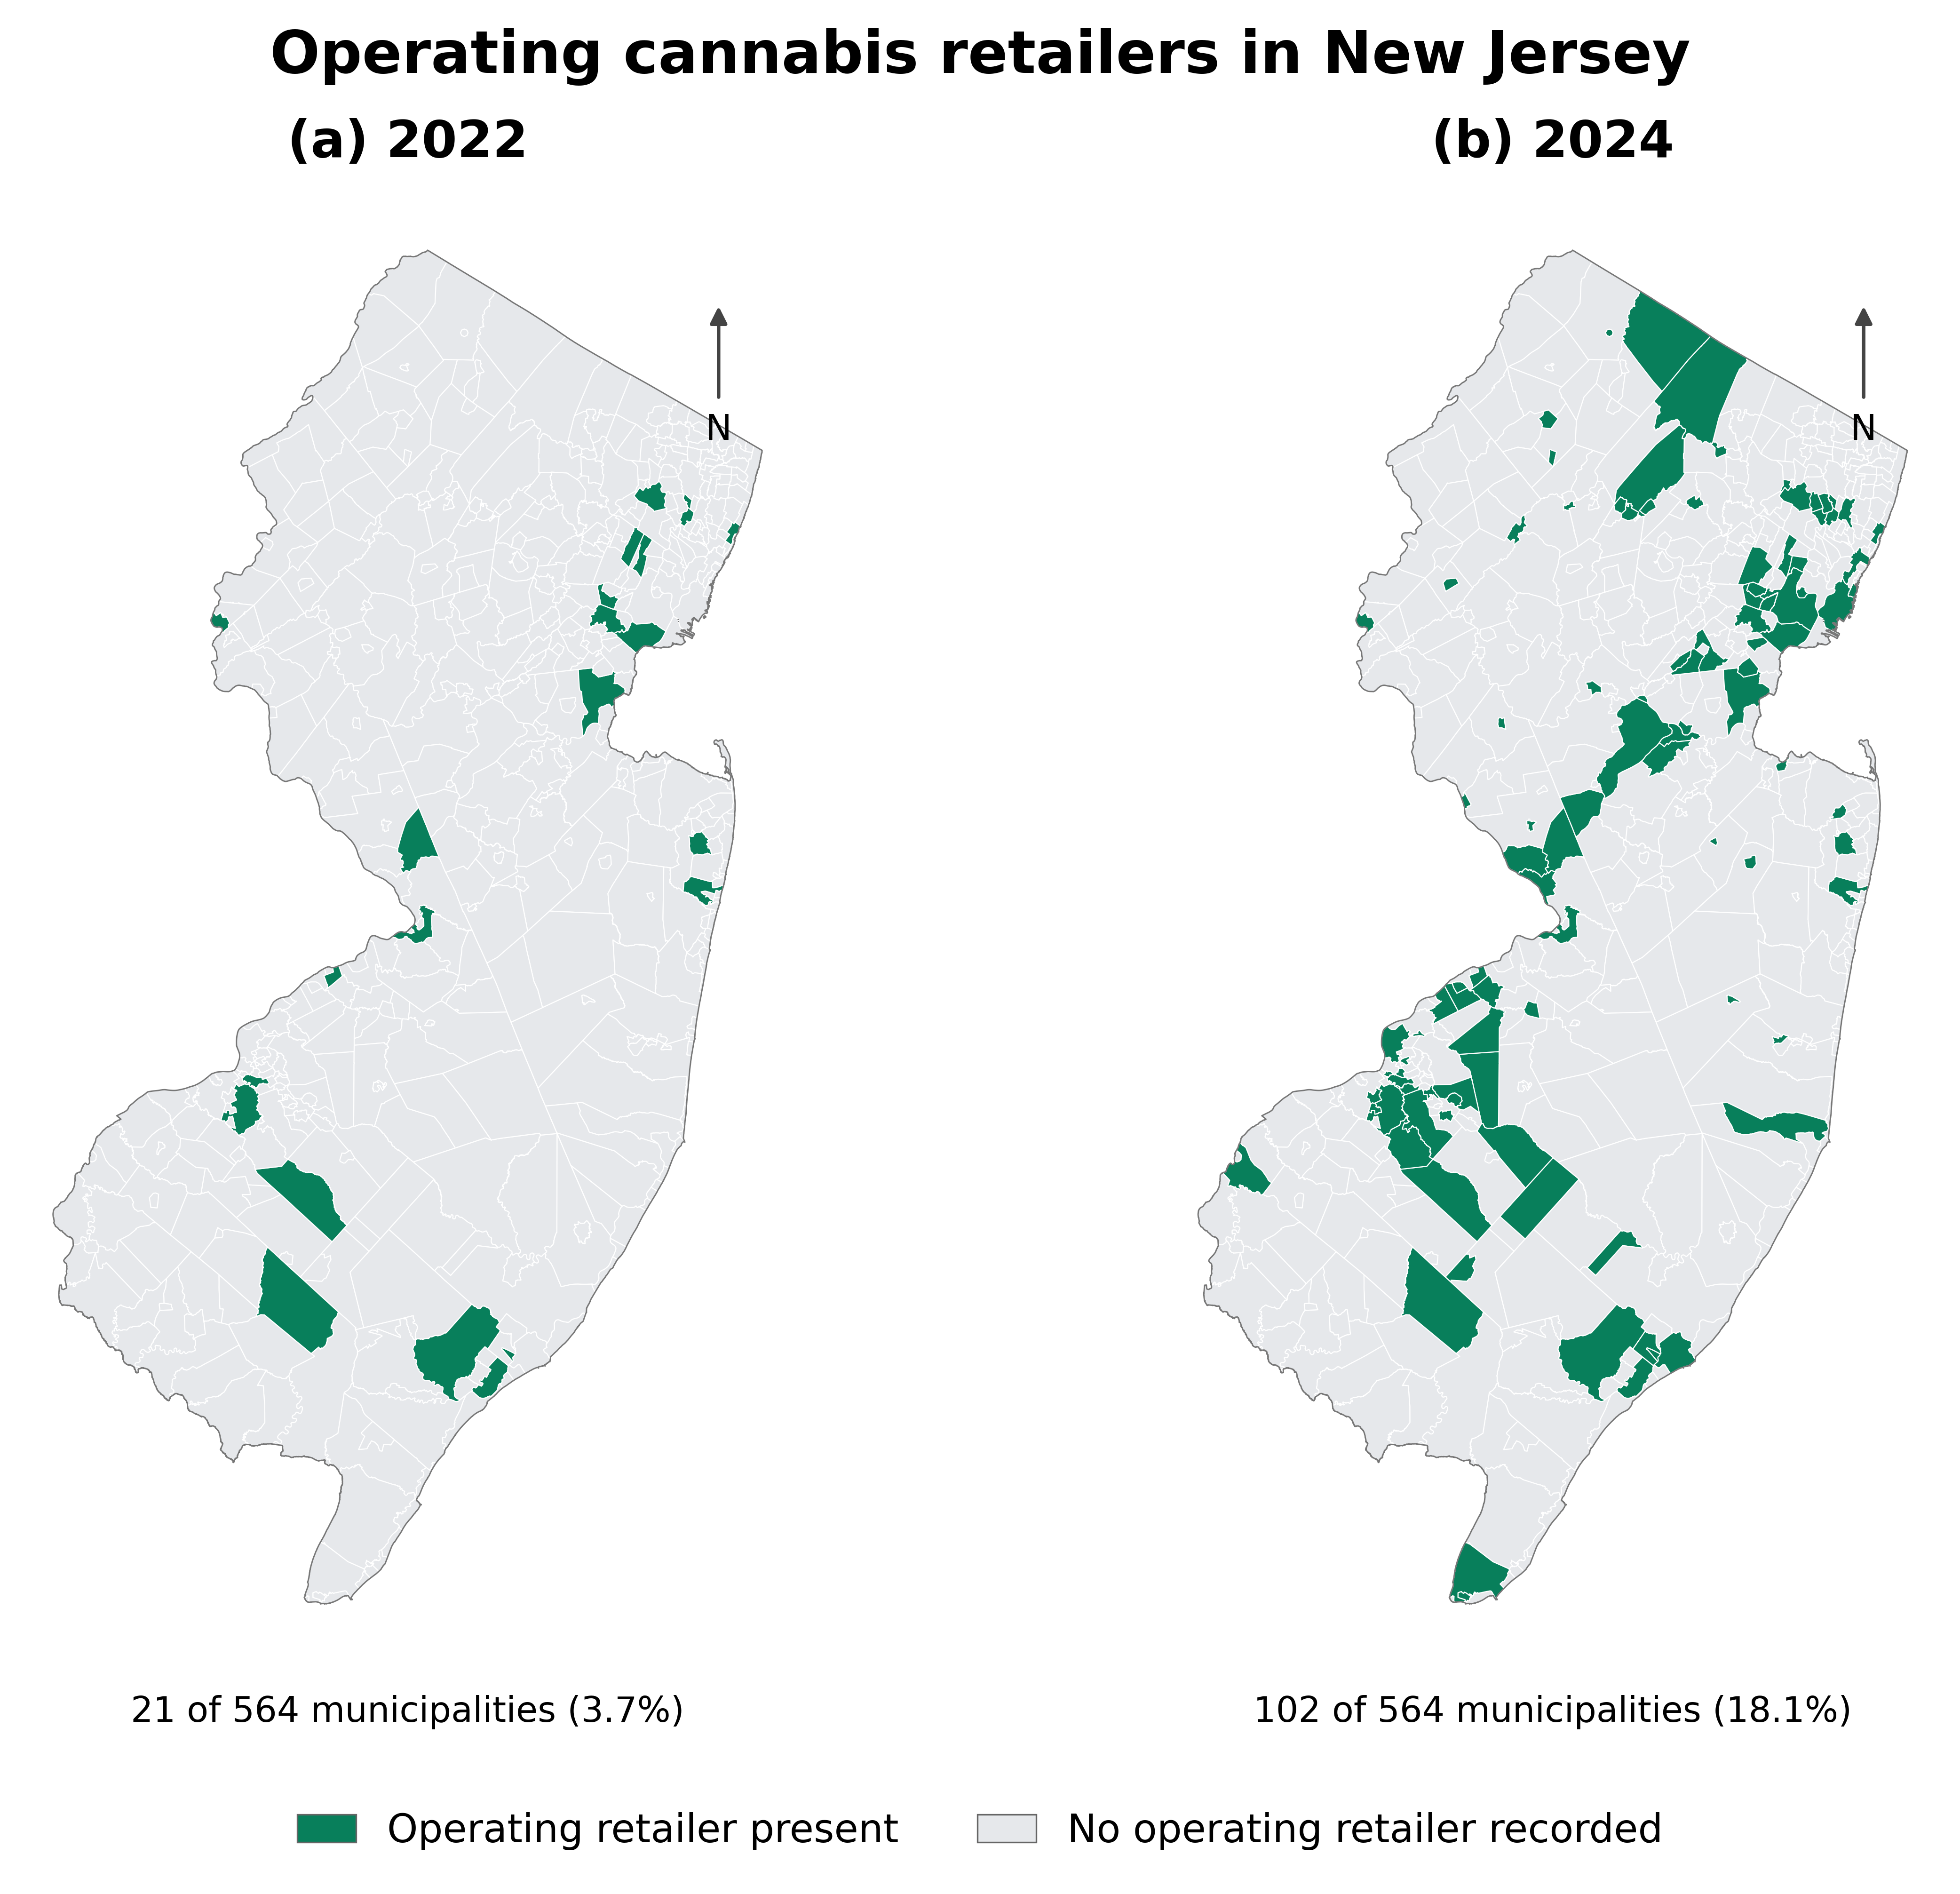

Figure 1 complete; all 564 municipalities matched in both years.


In [ ]:
# Save a clean standalone notebook and downloadable publication package.
from IPython.display import display, Image, FileLink
from zipfile import ZipFile, ZIP_DEFLATED
setup_source = "# Standalone Figure 1 setup: uses the reviewed Week 7 panel saved with the maps.\nfrom pathlib import Path\nfrom google.colab import drive\ndrive.mount('/content/drive')\nimport pandas as pd\nimport geopandas as gpd\nimport hashlib, json\nPROJECT = Path('/content/drive/MyDrive/2026_Dr. Hayes_SummerProjects/CannabisGISproject')\nGIS = PROJECT / 'NJ_Municipal_Boundaries_3424'\nPANEL_SOURCE = PROJECT / 'publication_figures_2026_11_02/Figure1/canexp_panel_new_source.dta'\nassert hashlib.sha256(PANEL_SOURCE.read_bytes()).hexdigest() == '3ea98a3cea1a5e35b1025b2a58b6e6738b47e8311821a57bde214ea040d11535'\nfigure1_panel = pd.read_stata(PANEL_SOURCE, convert_categoricals=False)\nfigure1_panel = figure1_panel.loc[figure1_panel.year.isin([2022,2024]), ['muni_id','muni_name','year','ret_any','ret_cnt']].copy()\nfigure1_panel['muni_id'] = figure1_panel.muni_id.astype(str).str.zfill(4)\nfigure1_boundaries = gpd.read_file(GIS / 'NJ_Municipal_Boundaries_3424.shp')\nreference = pd.read_csv(GIS / 'created_datasets/mun_geo.csv', dtype={'muni_id':str})\n"
map_source = "# Figure 1. Retailer presence by municipality, 2022 and 2024.\n# Use SSN: MUN_CODE is a different identifier for several municipalities.\nimport re, shutil\nimport numpy as np\nimport matplotlib.pyplot as plt\nfrom matplotlib.patches import Patch\nfrom pyproj import CRS\n\nFIGURE_DIR = PROJECT / 'publication_figures_2026_11_02' / 'Figure1'\nFIGURE_DIR.mkdir(parents=True, exist_ok=True)\nfigure1_panel['year'] = figure1_panel.year.astype(int)\nassert not figure1_panel.duplicated(['muni_id','year']).any()\nassert figure1_panel.groupby('year').size().to_dict() == {2022:564,2024:564}\nassert figure1_panel.ret_any.isin([0,1]).all()\nassert figure1_panel.ret_any.eq(figure1_panel.ret_cnt.gt(0).astype(int)).all()\nboundaries = figure1_boundaries.copy()\nboundaries['muni_id'] = boundaries['SSN'].astype(str).str.zfill(4)\nassert boundaries.muni_id.is_unique\nassert set(boundaries.muni_id) == set(figure1_panel.muni_id) == set(reference.muni_id)\nassert not boundaries.geometry.isna().any()\nif not boundaries.geometry.is_valid.all():\n    boundaries.geometry = boundaries.geometry.make_valid()\nassert boundaries.geometry.is_valid.all()\n\ndef place_name(s):\n    s = re.sub(r'[^a-z0-9 ]',' ',str(s).lower())\n    s = re.sub(r'\\b(township|borough|boro|twp|city|town|village)\\b',' ',s)\n    return re.sub(r'\\s+',' ',s).strip()\nname_audit = boundaries[['muni_id','NAME']].merge(\n    figure1_panel.loc[figure1_panel.year.eq(2024),['muni_id','muni_name']],\n    on='muni_id', validate='one_to_one')\nname_errors = name_audit.loc[name_audit.NAME.map(place_name) != name_audit.muni_name.map(place_name)]\nassert name_errors.empty, name_errors.to_dict('records')\nname_audit.to_csv(FIGURE_DIR/'municipality_join_check.csv',index=False)\nfigure1_panel.to_csv(FIGURE_DIR/'figure1_mapping_input.csv',index=False)\nif PANEL_SOURCE.resolve() != (FIGURE_DIR/'canexp_panel_new_source.dta').resolve():\n    shutil.copy2(PANEL_SOURCE, FIGURE_DIR/'canexp_panel_new_source.dta')\n\nplt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'pdf.fonttype':42,'svg.fonttype':'none'})\nCOLORS = {0:'#E6E8EB',1:'#087F5B'}\nlegend_items = [Patch(facecolor=COLORS[1],edgecolor='#666666',linewidth=.4,label='Operating retailer present'),\n                Patch(facecolor=COLORS[0],edgecolor='#666666',linewidth=.4,label='No operating retailer recorded')]\nbox = boundaries.total_bounds\npadx = (box[2]-box[0])*.035\npady = (box[3]-box[1])*.04\noutline = boundaries.geometry.union_all()\njoined = {}\nsummary = []\nfor year in [2022,2024]:\n    t = boundaries.merge(figure1_panel.loc[figure1_panel.year.eq(year)],on='muni_id',how='outer',validate='one_to_one',indicator=True)\n    assert t['_merge'].eq('both').all()\n    assert len(t)==564 and t.ret_any.notna().all()\n    joined[year] = t\n    n = int(t.ret_any.sum())\n    summary.append({'year':year,'municipalities':len(t),'retailer_municipalities':n,\n                    'without_retailers':len(t)-n,'percent_with_retailers':100*n/len(t),'retail_sites':int(t.ret_cnt.sum())})\n\ndef draw_map(ax,year,panel_label=''):\n    t=joined[year]\n    t.plot(ax=ax,color=t.ret_any.map(COLORS),edgecolor='#FFFFFF',linewidth=.27,zorder=1)\n    gpd.GeoSeries([outline],crs=boundaries.crs).boundary.plot(ax=ax,color='#777777',linewidth=.35,zorder=2)\n    ax.set_xlim(box[0]-padx,box[2]+padx)\n    ax.set_ylim(box[1]-pady,box[3]+pady)\n    ax.set_aspect('equal')\n    ax.axis('off')\n    ax.set_title((panel_label+' ' if panel_label else '')+str(year),fontweight='bold',fontsize=13,pad=10)\n    n=int(t.ret_any.sum())\n    ax.text(.5,-.025,f'{n} of 564 municipalities ({100*n/564:.1f}%)',transform=ax.transAxes,ha='center',va='top',fontsize=9)\n    # North arrow; projected State Plane north approximates true north here.\n    ax.annotate('N',xy=(.91,.93),xytext=(.91,.84),xycoords='axes fraction',ha='center',va='center',fontsize=9,\n                arrowprops={'arrowstyle':'-|>','color':'#444444','lw':.9})\n\nfig,axes=plt.subplots(1,2,figsize=(8.3,7.0))\nfig.subplots_adjust(left=.025,right=.975,top=.88,bottom=.14,wspace=.06)\nfig.suptitle('Operating cannabis retailers in New Jersey',fontsize=15,fontweight='bold',y=.965)\nfor ax,year,label in zip(axes,[2022,2024],['(a)','(b)']):draw_map(ax,year,label)\nfig.legend(handles=legend_items,loc='lower center',bbox_to_anchor=(.5,.025),ncol=2,frameon=False,fontsize=10,handlelength=1.5,columnspacing=2)\nfor ext in ['png','pdf','svg']:\n    fig.savefig(FIGURE_DIR/f'Figure1_Retailer_Presence_2022_2024.{ext}',dpi=600,facecolor='white',bbox_inches='tight',pad_inches=.1)\nplt.show()\nfor year in [2022,2024]:\n    single,ax=plt.subplots(figsize=(4.7,7.0))\n    single.subplots_adjust(left=.035,right=.965,top=.92,bottom=.16)\n    draw_map(ax,year)\n    single.legend(handles=legend_items,loc='lower center',bbox_to_anchor=(.5,.02),ncol=1,frameon=False,fontsize=10)\n    for ext in ['png','pdf','svg']:\n        single.savefig(FIGURE_DIR/f'Figure1_Retailer_Presence_{year}.{ext}',dpi=600,facecolor='white',bbox_inches='tight',pad_inches=.1)\n    plt.close(single)\nsummary=pd.DataFrame(summary)\nsummary.to_csv(FIGURE_DIR/'figure1_counts.csv',index=False)\ncaption=('Figure 1. Geographic distribution of operating cannabis retailers in New Jersey, 2022 and 2024. '\n         'Notes: Green municipalities have at least one recorded operating adult-use retailer (ret_any = 1); '\n         'gray municipalities have no operating retailer recorded in the reviewed panel (ret_any = 0). '\n         'Both panels use the same 564-municipality geography, extent, colors and calendar-year retailer-count convention. '\n         'Opening dates rely on the documented license-commencement proxy and agreed relocation rules. '\n         'Colors indicate retailer presence, not municipal permission or the number of stores. '\n         'Pine Valley is incorporated in the common Pine Hill geography. '\n         'Source: canexp_panel_new.dta, reviewed Week 7 analysis dataset; NJ municipal boundary layer from the existing GIS project (EPSG:3424), joined using SSN.')\n(FIGURE_DIR/'Figure1_caption.txt').write_text(caption)\nprovenance={'source_sha256':hashlib.sha256(PANEL_SOURCE.read_bytes()).hexdigest(),\n            'mapping_variable':'ret_any','boundary_identifier':'SSN','all_564_municipalities_matched':True,\n            'name_mismatches':len(name_errors),'counts':summary.to_dict('records')}\n(FIGURE_DIR/'figure1_checks.json').write_text(json.dumps(provenance,indent=2))\nprint(summary.to_string(index=False))\nprint('Verified exact 564-polygon matches for both years. Name mismatches:',len(name_errors))\nprint('Saved to:',FIGURE_DIR)\n"
notebook = {'nbformat':4,'nbformat_minor':5,'metadata':{'colab':{'provenance':[]},'kernelspec':{'display_name':'Python 3','name':'python3'},'language_info':{'name':'python'}},'cells':[{'cell_type':'markdown','metadata':{},'source':['# Figure 1 New Jersey retailer presence in 2022 and 2024\n','Uses ret_any from the reviewed Week 7 panel. Green indicates recorded retailer presence; gray indicates no recorded retailer. This notebook does not use opted_in or external-demand categories.\n']},{'cell_type':'code','metadata':{},'execution_count':None,'outputs':[],'source':setup_source.splitlines(keepends=True)},{'cell_type':'code','metadata':{},'execution_count':None,'outputs':[],'source':map_source.splitlines(keepends=True)}]}
(FIGURE_DIR/'Figure1_Retailer_Presence_2022_2024.ipynb').write_text(json.dumps(notebook,indent=2))
(FIGURE_DIR/'figure1_map.py').write_text(setup_source+'\n'+map_source)
print('Figure files:',[p.name for p in FIGURE_DIR.iterdir()])
package = Path('/content/Figure1_Publication_Maps_2022_2024.zip')
with ZipFile(package,'w',ZIP_DEFLATED) as archive:
    for p in FIGURE_DIR.iterdir():
        if p.is_file(): archive.write(p,arcname=p.name)
print('ZIP:',package,package.stat().st_size,'bytes')
display(Image(filename=str(FIGURE_DIR/'Figure1_Retailer_Presence_2022_2024.png'),width=900))
print('Figure 1 complete; all 564 municipalities matched in both years.')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


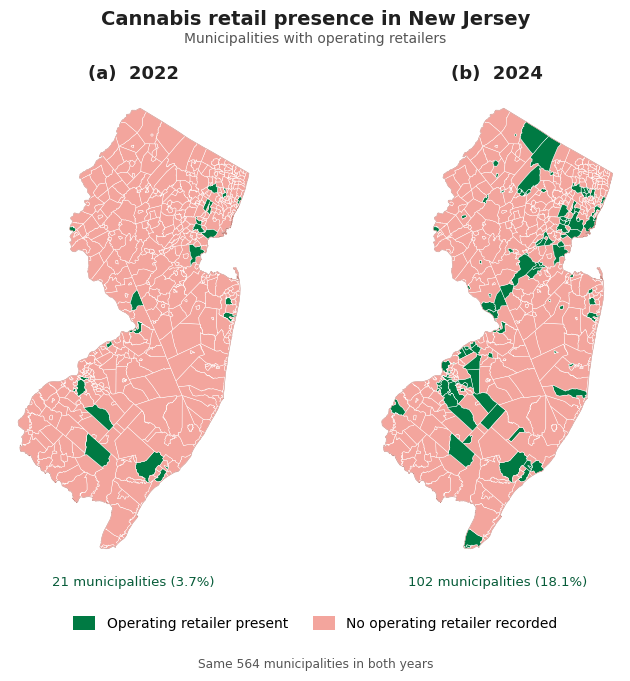

 year  municipalities  retailer_municipalities  without_retailers  percent_with_retailers  retail_sites
 2022             564                       21                543                3.723404            21
 2024             564                      102                462               18.085106           207
Verified exact 564-polygon matches for both years. Name mismatches: 0
Saved to: /content/drive/MyDrive/2026_Dr. Hayes_SummerProjects/CannabisGISproject/publication_figures_2026_11_02/Figure1_Revised
Revised maps saved. Same data and counts: [{'year': 2022, 'municipalities': 564, 'retailer_municipalities': 21, 'without_retailers': 543, 'percent_with_retailers': 3.723404255319149, 'retail_sites': 21}, {'year': 2024, 'municipalities': 564, 'retailer_municipalities': 102, 'without_retailers': 462, 'percent_with_retailers': 18.085106382978722, 'retail_sites': 207}]
Package: /content/Figure1_Revised_Maps_2022_2024.zip


In [ ]:
# Revised Figure 1: coral background and stronger green, matching the reference.
from pathlib import Path
import json, hashlib
PROJECT = Path('/content/drive/MyDrive/2026_Dr. Hayes_SummerProjects/CannabisGISproject')
original = PROJECT / 'publication_figures_2026_11_02/Figure1'
new_source = (original/'figure1_map.py').read_text()
new_source = new_source.replace("FIGURE_DIR = PROJECT / 'publication_figures_2026_11_02' / 'Figure1'", "FIGURE_DIR = PROJECT / 'publication_figures_2026_11_02' / 'Figure1_Revised'")
new_source = new_source.replace("COLORS = {0:'#E6E8EB',1:'#087F5B'}", "COLORS = {0:'#F3A59D',1:'#007A43'}")
new_source = new_source.replace("edgecolor='#666666',linewidth=.4,label='Operating retailer present'", "edgecolor='none',label='Operating retailer present'")
new_source = new_source.replace("edgecolor='#666666',linewidth=.4,label='No operating retailer recorded'", "edgecolor='none',label='No operating retailer recorded'")
plot_source = "def draw_map(ax, year, panel_label=''):\n    t = joined[year]\n    t.plot(ax=ax, color=t.ret_any.map(COLORS), edgecolor='white', linewidth=.32, zorder=1)\n    gpd.GeoSeries([outline], crs=boundaries.crs).boundary.plot(ax=ax, color='#C68880', linewidth=.35, zorder=2)\n    ax.set_xlim(box[0]-padx, box[2]+padx)\n    ax.set_ylim(box[1]-pady, box[3]+pady)\n    ax.set_aspect('equal')\n    ax.axis('off')\n    ax.set_title((panel_label+'  ' if panel_label else '')+str(year), fontsize=13, fontweight='bold', color='#202020', pad=8)\n    n = int(t.ret_any.sum())\n    ax.text(.5,-.02,f'{n} municipalities ({100*n/564:.1f}%)',transform=ax.transAxes,ha='center',va='top',fontsize=9.5,color='#075C39',fontweight='medium')\n\nfig, axes = plt.subplots(1,2,figsize=(7.6,7.0))\nfig.subplots_adjust(left=.025,right=.975,top=.85,bottom=.17,wspace=.015)\nfig.suptitle('Cannabis retail presence in New Jersey',fontsize=14,fontweight='bold',color='#202020',y=.965)\nfig.text(.5,.918,'Municipalities with operating retailers',ha='center',fontsize=10,color='#555555')\nfor ax,year,label in zip(axes,[2022,2024],['(a)','(b)']): draw_map(ax,year,label)\nfig.legend(handles=legend_items,loc='lower center',bbox_to_anchor=(.5,.06),ncol=2,frameon=False,fontsize=10,handlelength=1.6,handleheight=1.15,columnspacing=1.8)\nfig.text(.5,.025,'Same 564 municipalities in both years',ha='center',fontsize=8.8,color='#555555')\nfor ext in ['png','pdf','svg']:\n    fig.savefig(FIGURE_DIR/f'Figure1_Retailer_Presence_2022_2024.{ext}',dpi=600,facecolor='white',bbox_inches='tight',pad_inches=.12)\nplt.show()\nfor year in [2022,2024]:\n    single,ax=plt.subplots(figsize=(4.5,6.8))\n    single.subplots_adjust(left=.045,right=.955,top=.90,bottom=.19)\n    draw_map(ax,year)\n    single.legend(handles=legend_items,loc='lower center',bbox_to_anchor=(.5,.035),ncol=1,frameon=False,fontsize=10,handlelength=1.6,handleheight=1.15,labelspacing=.65)\n    for ext in ['png','pdf','svg']:\n        single.savefig(FIGURE_DIR/f'Figure1_Retailer_Presence_{year}.{ext}',dpi=600,facecolor='white',bbox_inches='tight',pad_inches=.12)\n    plt.close(single)\n"
start = new_source.index('def draw_map(')
stop = new_source.index('summary=pd.DataFrame(summary)')
new_source = new_source[:start] + plot_source + new_source[stop:]
new_source = new_source.replace('gray municipalities', 'coral municipalities')
exec(compile(new_source,'figure1_revised.py','exec'))
(FIGURE_DIR/'figure1_map.py').write_text(new_source)
notebook = {'nbformat':4,'nbformat_minor':5,'metadata':{'colab':{'provenance':[]},'kernelspec':{'display_name':'Python 3','name':'python3'},'language_info':{'name':'python'}},'cells':[{'cell_type':'markdown','metadata':{},'source':['# Figure 1 revised publication maps\n','Coral indicates no recorded retailer; green indicates retailer presence. Counts and source data are unchanged.\n']},{'cell_type':'code','metadata':{},'execution_count':None,'outputs':[],'source':new_source.splitlines(keepends=True)}]}
(FIGURE_DIR/'Figure1_Retailer_Presence_2022_2024.ipynb').write_text(json.dumps(notebook,indent=2))
from zipfile import ZipFile,ZIP_DEFLATED
revised_zip = Path('/content/Figure1_Revised_Maps_2022_2024.zip')
with ZipFile(revised_zip,'w',ZIP_DEFLATED) as z:
    for p in FIGURE_DIR.iterdir():
        if p.is_file(): z.write(p,arcname=p.name)
print('Revised maps saved. Same data and counts:',summary.to_dict('records'))
print('Package:',revised_zip)


In [9]:
# Larger individual maps with light pink background and county counts.
from pathlib import Path
from google.colab import drive
drive.mount('/content/drive')
import json
PROJECT = Path('/content/drive/MyDrive/2026_Dr. Hayes_SummerProjects/CannabisGISproject')
src=(PROJECT/'publication_figures_2026_11_02/Figure1_Revised/figure1_map.py').read_text()
src=src.replace("/ 'Figure1_Revised'", "/ 'Figure1_County_Maps'")
start=src.index('def draw_map(')
stop=src.index('summary=pd.DataFrame(summary)')
plot_code="from matplotlib import patheffects as pe\ncounties = boundaries[['COUNTY','geometry']].dissolve(by='COUNTY')\nassert len(counties) == 21\ncounty_counts = pd.concat([joined[y].groupby('COUNTY').agg(retailers=('ret_cnt','sum'),retailer_municipalities=('ret_any','sum')).assign(year=y).reset_index() for y in [2022,2024]],ignore_index=True)\ncounty_counts['retailers'] = county_counts.retailers.astype(int)\nassert county_counts.groupby('year').retailers.sum().to_dict() == {2022:21,2024:207}\ncounty_counts.to_csv(FIGURE_DIR/'county_retailer_counts.csv',index=False)\nboundaries.to_file(FIGURE_DIR/'municipal_boundaries.geojson',driver='GeoJSON')\nCOLORS = {0:'#FBE5E2',1:'#007A43'}\nlegend_items = [Patch(facecolor=COLORS[1],label='Municipality with operating retailer(s)'),Patch(facecolor=COLORS[0],label='No operating retailer recorded')]\nfor year in [2022,2024]:\n    fig,ax = plt.subplots(figsize=(8.5,11))\n    fig.subplots_adjust(left=.035,right=.965,top=.88,bottom=.14)\n    joined[year].plot(ax=ax,color=joined[year].ret_any.map(COLORS),edgecolor='white',linewidth=.35,zorder=1)\n    counties.boundary.plot(ax=ax,color='white',linewidth=2.4,zorder=2)\n    counties.boundary.plot(ax=ax,color='#777777',linewidth=.85,zorder=3)\n    ax.set_xlim(box[0]-padx,box[2]+padx*3.5)\n    ax.set_ylim(box[1]-pady*.35,box[3]+pady*.35)\n    ax.set_aspect('equal'); ax.axis('off')\n    for county,row in counties.iterrows():\n        p=row.geometry.centroid\n        x,y=p.x,p.y\n        count=int(county_counts.loc[(county_counts.COUNTY==county)&(county_counts.year==year),'retailers'].iloc[0])\n        label=county.title()+'\\n'+str(count)\n        if county=='HUDSON':\n            x=box[2]+padx*1.3\n            ax.annotate(label,xy=(p.x,p.y),xytext=(x,p.y),ha='center',va='center',fontsize=8.8,color='#202020',fontweight='bold',linespacing=1.35,arrowprops=dict(arrowstyle='-',color='#666666',lw=.7),path_effects=[pe.withStroke(linewidth=2.5,foreground='white')],zorder=5)\n        else:\n            ax.text(x,y,label,ha='center',va='center',fontsize=8.8,color='#202020',fontweight='bold',linespacing=1.35,path_effects=[pe.withStroke(linewidth=2.5,foreground='white')],zorder=5)\n    total=int(joined[year].ret_cnt.sum()); n=int(joined[year].ret_any.sum())\n    fig.suptitle('Operating cannabis retailers in New Jersey',fontsize=17,fontweight='bold',y=.965,color='#202020')\n    fig.text(.5,.929,str(year),ha='center',fontsize=16,fontweight='bold',color='#075C39')\n    fig.text(.5,.902,f'{total} retailers across {n} municipalities',ha='center',fontsize=11,color='#444444')\n    fig.legend(handles=legend_items,loc='lower center',bbox_to_anchor=(.5,.065),frameon=False,fontsize=11,labelspacing=.8,handleheight=1.2)\n    fig.text(.5,.025,'County labels show the number of operating retailers.\\nThick outlines mark counties; thin white lines mark municipalities.',ha='center',fontsize=9.5,color='#555555',linespacing=1.5)\n    for ext in ['png','pdf','svg']:\n        fig.savefig(FIGURE_DIR/f'Figure1_Retailers_County_{year}.{ext}',dpi=600,facecolor='white',bbox_inches='tight',pad_inches=.15)\n    plt.close(fig)\n"
src=src[:start]+plot_code+src[stop:]
src=src.replace('coral municipalities','light pink municipalities')
src=src.replace('Colors indicate retailer presence, not municipal permission or the number of stores. ', 'Colors indicate municipal retailer presence. County labels sum operating retailer counts (ret_cnt), not the number of host municipalities. Thick boundaries mark counties. ')
exec(compile(src,'figure1_county_maps.py','exec'))
(FIGURE_DIR/'figure1_map.py').write_text(src)
nb={'nbformat':4,'nbformat_minor':5,'metadata':{'kernelspec':{'display_name':'Python 3','name':'python3'}},'cells':[{'cell_type':'markdown','metadata':{},'source':['# Figure 1: municipal retailer presence and county retailer counts\n','Light pink and green show municipality-level presence; numeric labels are county totals.\n']},{'cell_type':'code','metadata':{},'execution_count':None,'outputs':[],'source':src.splitlines(keepends=True)}]}
(FIGURE_DIR/'Figure1_County_Maps.ipynb').write_text(json.dumps(nb,indent=2))
from zipfile import ZipFile,ZIP_DEFLATED
package=Path('/content/Figure1_County_Maps_2022_2024.zip')
with ZipFile(package,'w',ZIP_DEFLATED) as z:
    for p in FIGURE_DIR.iterdir():
        if p.is_file(): z.write(p,arcname=p.name)
print(county_counts.to_string(index=False))
print('Saved:',package)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
 year  municipalities  retailer_municipalities  without_retailers  percent_with_retailers  retail_sites
 2022             564                       21                543                3.723404            21
 2024             564                      102                462               18.085106           207
Verified exact 564-polygon matches for both years. Name mismatches: 0
Saved to: /content/drive/MyDrive/2026_Dr. Hayes_SummerProjects/CannabisGISproject/publication_figures_2026_11_02/Figure1_County_Maps
    COUNTY  retailers  retailer_municipalities  year
  ATLANTIC          1                        1  2022
    BERGEN          3                        3  2022
BURLINGTON          2                        2  2022
    CAMDEN     